# BurnInWatch — Context-Aware Feature Engineering v2

## What we learned from v1

The first window-level feature matrix is working, but it is intentionally **over-complete**.

Examples of redundancy:
- `supplyVoltage_*` and `node1Voltage_*` are almost duplicates.
- Mean/median/quantiles of the same very stable signal are highly correlated.
- `heatSinkTemperature_*` and `internalTemperature_*` also show extremely strong relationships.

The feature matrix currently describes each 100-event window, which is good, but the next step is to build a **compact engineering feature set**.

### Core principle

BurnInWatch should not call a changing stress condition an anomaly.

Therefore we separate:

**Operating context**
- supply voltage
- applied/observed voltage regime

from:

**Component response**
- collector-emitter current
- node voltage behavior
- package temperature behavior
- stability / variation

And we add **relative-to-baseline** and **context-aware residual** features.

This notebook creates candidate features only. It still does not train the anomaly detector.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import HuberRegressor
from sklearn.pipeline import make_pipeline

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

PROCESSED = Path("processed")
INPUT = PROCESSED / "burninwatch_window_features_v1.csv"

features = pd.read_csv(INPUT)

print("Input shape:", features.shape)
display(features.head())

Input shape: (687, 82)


,device_id,file_name,window_index,window_size,window_start_event,window_end_event,window_start_seconds,window_end_seconds,file_role,supplyVoltage_mean,supplyVoltage_median,supplyVoltage_std,supplyVoltage_min,supplyVoltage_max,supplyVoltage_q05,supplyVoltage_q95,supplyVoltage_iqr,supplyVoltage_mad,supplyVoltage_slope,node1Voltage_mean,node1Voltage_median,node1Voltage_std,node1Voltage_min,node1Voltage_max,node1Voltage_q05,node1Voltage_q95,node1Voltage_iqr,node1Voltage_mad,node1Voltage_slope,node2Voltage_mean,node2Voltage_median,node2Voltage_std,node2Voltage_min,node2Voltage_max,node2Voltage_q05,node2Voltage_q95,node2Voltage_iqr,node2Voltage_mad,node2Voltage_slope,collectorEmitterCurrent_mean,collectorEmitterCurrent_median,collectorEmitterCurrent_std,collectorEmitterCurrent_min,collectorEmitterCurrent_max,collectorEmitterCurrent_q05,collectorEmitterCurrent_q95,collectorEmitterCurrent_iqr,collectorEmitterCurrent_mad,collectorEmitterCurrent_slope,heatSinkTemperature_mean,heatSinkTemperature_median,heatSinkTemperature_std,heatSinkTemperature_min,heatSinkTemperature_max,heatSinkTemperature_q05,heatSinkTemperature_q95,heatSinkTemperature_iqr,heatSinkTemperature_mad,heatSinkTemperature_slope,packageTemperature_mean,packageTemperature_median,packageTemperature_std,packageTemperature_min,packageTemperature_max,packageTemperature_q05,packageTemperature_q95,packageTemperature_iqr,packageTemperature_mad,packageTemperature_slope,internalTemperature_mean,internalTemperature_median,internalTemperature_std,internalTemperature_min,internalTemperature_max,internalTemperature_q05,internalTemperature_q95,internalTemperature_iqr,internalTemperature_mad,internalTemperature_slope,supply_node1_mean_diff,node1_node2_mean_diff,estimated_power_proxy
0,Device_2,Device2 1.mat,0,100,1,100,0.000,22.671,main,2.454372,2.457497,0.006901,2.442149,2.467264,2.443545,2.461683,0.012557,0.004186,0.000159,2.451358,2.453527,0.006792,2.439020,2.459744,2.441783,2.459744,0.014162,0.004836,0.000209,1.952854,1.942535,0.103817,1.737816,2.132039,1.791762,2.115578,0.139707,0.076770,0.005401,0.118606,0.089582,0.056871,-0.019777,0.406723,0.080834,0.174992,0.072177,0.006562,0.000347,718.801894,718.801617,0.005683,718.787773,718.815463,718.792387,718.810847,0.009230,0.004615,-0.000003,44.674700,43.873651,10.876925,30.080334,64.855038,30.402502,62.593386,19.625527,9.786456,1.644183,-2254.175125,-2254.156325,0.137230,-2254.488002,-2253.824736,-2254.377433,-2253.935256,0.221089,0.110549,-0.003440,0.003014,0.498504,0.231621
1,Device_2,Device2 1.mat,1,100,101,200,22.911,45.542,main,2.454399,2.456102,0.006417,2.440754,2.463078,2.444940,2.461683,0.012557,0.005581,-0.000067,2.452007,2.454218,0.006048,2.441783,2.459744,2.444477,2.459744,0.012435,0.005526,-0.000080,2.026345,2.037978,0.088584,1.849858,2.158320,1.880220,2.137987,0.156998,0.073312,0.001211,0.119897,0.114735,0.048703,-0.078830,0.402349,0.083021,0.164384,0.063428,0.029527,-0.000851,718.804063,718.806232,0.005998,718.787773,718.815463,718.792387,718.810847,0.004615,0.004615,0.000091,78.068621,78.785971,6.957067,65.227393,88.944789,66.747572,88.169319,11.951787,5.876734,1.054713,-2254.198341,-2254.156325,0.145637,-2254.598579,-2253.824736,-2254.377433,-2253.935256,0.221089,0.110549,-0.001484,0.002392,0.425662,0.242952
2,Device_2,Device2 1.mat,2,100,201,300,45.776,68.042,main,2.456576,2.458892,0.005668,2.446335,2.464473,2.446335,2.463078,0.009767,0.002790,0.000213,2.454301,2.456981,0.006276,2.441783,2.463889,2.443165,2.461195,0.011398,0.002763,0.000270,2.117639,2.065643,0.192635,1.899655,2.462633,1.917568,2.461318,0.195728,0.098210,0.016992,0.107692,0.089582,0.039220,-0.039461,0.297364,0.085099,0.157494,0.056867,0.004374,-0.001148,718.806971,718.806232,0.005489,718.792387,718.815463,718.797002,718.815463,0.009231,0.004615,0.000221,96.348991,96.829005,3.567825,89.284765,101.022049,90.350834,100.860965,6.200524,3.011220,0.542141,-2254.294520,-2254.266875,0.133011,-2254.709167,-2253.935256,-2254.488002,-2254.045786,0.110559,0.110559,-0

## 1. Define the first compact feature groups

We intentionally do not carry every mean/median/min/max/quantile into the model.

For the first candidate set we keep features that have a distinct interpretation:

### Operating context
- supply voltage level
- supply voltage variability

### Electrical response
- node2 voltage level and variability
- collector-emitter current level
- current variability
- current tails / spread
- current trend

### Thermal response
- package temperature level
- temperature variability
- temperature trend

### Relationships
- supply-to-node1 deviation
- node1-to-node2 deviation
- current / node2-voltage response proxy

In [2]:
# ============================================================
# 1. COMPACT CORE FEATURES
# ============================================================

CORE_FEATURES = [
    # operating context
    "supplyVoltage_mean",
    "supplyVoltage_std",

    # electrical response
    "node2Voltage_mean",
    "node2Voltage_std",
    "node2Voltage_iqr",
    "node2Voltage_slope",

    "collectorEmitterCurrent_mean",
    "collectorEmitterCurrent_std",
    "collectorEmitterCurrent_q05",
    "collectorEmitterCurrent_q95",
    "collectorEmitterCurrent_iqr",
    "collectorEmitterCurrent_slope",

    # thermal response
    "packageTemperature_mean",
    "packageTemperature_std",
    "packageTemperature_q05",
    "packageTemperature_q95",
    "packageTemperature_iqr",
    "packageTemperature_slope",

    # relationships created in v1
    "supply_node1_mean_diff",
    "node1_node2_mean_diff",
    "estimated_power_proxy",
]

CORE_FEATURES = [
    c for c in CORE_FEATURES
    if c in features.columns
]

core = features[
    [
        "device_id",
        "file_name",
        "file_role",
        "window_index",
        "window_size",
        "window_start_seconds",
        "window_end_seconds",
    ] + CORE_FEATURES
].copy()

print("Core feature count:", len(CORE_FEATURES))
display(core.head())

Core feature count: 21


,device_id,file_name,file_role,window_index,window_size,window_start_seconds,window_end_seconds,supplyVoltage_mean,supplyVoltage_std,node2Voltage_mean,node2Voltage_std,node2Voltage_iqr,node2Voltage_slope,collectorEmitterCurrent_mean,collectorEmitterCurrent_std,collectorEmitterCurrent_q05,collectorEmitterCurrent_q95,collectorEmitterCurrent_iqr,collectorEmitterCurrent_slope,packageTemperature_mean,packageTemperature_std,packageTemperature_q05,packageTemperature_q95,packageTemperature_iqr,packageTemperature_slope,supply_node1_mean_diff,node1_node2_mean_diff,estimated_power_proxy
0,Device_2,Device2 1.mat,main,0,100,0.000,22.671,2.454372,0.006901,1.952854,0.103817,0.139707,0.005401,0.118606,0.056871,0.080834,0.174992,0.072177,0.000347,44.674700,10.876925,30.402502,62.593386,19.625527,1.644183,0.003014,0.498504,0.231621
1,Device_2,Device2 1.mat,main,1,100,22.911,45.542,2.454399,0.006417,2.026345,0.088584,0.156998,0.001211,0.119897,0.048703,0.083021,0.164384,0.063428,-0.000851,78.068621,6.957067,66.747572,88.169319,11.951787,1.054713,0.002392,0.425662,0.242952
2,Device_2,Device2 1.mat,main,2,100,45.776,68.042,2.456576,0.005668,2.117639,0.192635,0.195728,0.016992,0.107692,0.039220,0.085099,0.157494,0.056867,-0.001148,96.348991,3.567825,90.350834,100.860965,6.200524,0.542141,0.002275,0.336661,0.228053
3,Device_2,Device2 1.mat,main,3,100,68.282,90.812,2.457120,0.005396,2.097679,0.151077,0.127604,-0.009018,0.110033,0.038414,0.085208,0.159682,0.056867,0.001033,97.329904,1.702277,95.143693,100.038545,3.043599,0.046638,0.002626,0.356815,0.230813
4,Device_2,Device2 1.mat,main,4,100,91.050,113.501,2.457609,0.005506,2.171392,0.208924,0.456469,-0.023517,0.097325,0.032439,0.083021,0.157385,0.006562,0.000371,97.966307,1.998920,95.579187,101.089235,3.909730,-0.214554,0.001595,0.284622,0.211331


## 2. Add relative-to-file-start response features

Different devices begin from different absolute operating points.

For each source file, we calculate a baseline using the **median of the first 3 windows**.

This is an unsupervised assumption that is appropriate for burn-in screening:

> early measurements are treated as the initial reference state, not as a supplied healthy/fault label.

We calculate relative change only for component-response variables.
We do NOT use supply-voltage change as a degradation feature because supply voltage is part of the imposed operating condition.

In [3]:
# ============================================================
# 2. FILE-LOCAL BASELINES
# ============================================================

BASELINE_WINDOWS = 3

response_mean_fields = [
    "node2Voltage_mean",
    "collectorEmitterCurrent_mean",
    "packageTemperature_mean",
]

for field in response_mean_fields:
    baseline_name = field.replace("_mean", "_baseline")

    core[baseline_name] = (
        core.sort_values(
            ["device_id", "file_name", "window_index"]
        )
        .groupby(["device_id", "file_name"])[field]
        .transform(
            lambda s: s.iloc[:BASELINE_WINDOWS].median()
        )
    )

    delta_name = field.replace("_mean", "_delta_from_baseline")
    core[delta_name] = core[field] - core[baseline_name]

    pct_name = field.replace("_mean", "_pct_change_from_baseline")

    # Prevent division by extremely small baselines.
    denominator = core[baseline_name].abs().clip(lower=1e-9)
    core[pct_name] = core[delta_name] / denominator

display(
    core[
        [
            "device_id",
            "file_name",
            "window_index",
            "node2Voltage_mean",
            "node2Voltage_delta_from_baseline",
            "collectorEmitterCurrent_mean",
            "collectorEmitterCurrent_delta_from_baseline",
            "packageTemperature_mean",
            "packageTemperature_delta_from_baseline",
        ]
    ].head(15)
)

,device_id,file_name,window_index,node2Voltage_mean,node2Voltage_delta_from_baseline,collectorEmitterCurrent_mean,collectorEmitterCurrent_delta_from_baseline,packageTemperature_mean,packageTemperature_delta_from_baseline
0,Device_2,Device2 1.mat,0,1.952854,-0.073491,0.118606,0.000000,44.674700,-33.393921
1,Device_2,Device2 1.mat,1,2.026345,0.000000,0.119897,0.001290,78.068621,0.000000
2,Device_2,Device2 1.mat,2,2.117639,0.091294,0.107692,-0.010914,96.348991,18.280369
3,Device_2,Device2 1.mat,3,2.097679,0.071334,0.110033,-0.008574,97.329904,19.261282
4,Device_2,Device2 1.mat,4,2.171392,0.145046,0.097325,-0.021281,97.966307,19.897686
5,Device_2,Device2 1.mat,5,2.208131,0.181785,0.102924,-0.015682,98.112983,20.044362
6,Device_2,Device2 1.mat,6,2.305082,0.278736,0.110033,-0.008574,98.477405,20.408784
7,Device_2,Device2 1.mat,7,2.499883,0.473538,0.111192,-0.007415,108.763640,30.695019
8,Device_2,Device2 1.mat,8,2.515860,0.489514,0.111476,-0.007130,126.699679,48.631058
9,Device_2,Device2 1.mat,9,2.671460,0.645115,0.105461,-0.013145,135.770425,57.701804


## 3. Electrical response ratios

Absolute current is strongly dependent on operating conditions.

We therefore calculate simple response ratios:

- current per node2 voltage
- node1-to-node2 voltage drop

These are not claimed to be official device parameters; they are engineered screening indicators.

In [4]:
# ============================================================
# 3. RESPONSE RATIOS
# ============================================================

core["current_per_node2V"] = (
    core["collectorEmitterCurrent_mean"] /
    core["node2Voltage_mean"].abs().clip(lower=1e-6)
)

core["node_voltage_drop"] = (
    core["node1_node2_mean_diff"].abs()
)

display(
    core[
        [
            "collectorEmitterCurrent_mean",
            "node2Voltage_mean",
            "current_per_node2V",
            "node_voltage_drop"
        ]
    ].describe().T
)

,count,mean,std,min,25%,50%,75%,max
collectorEmitterCurrent_mean,687.0,0.106048,0.006106,0.083349,0.102782,0.106227,0.109508,0.155985
node2Voltage_mean,687.0,4.374847,1.089040,1.333053,3.616392,4.634704,5.109833,5.925280
current_per_node2V,687.0,0.026564,0.010137,0.015274,0.020461,0.022410,0.028843,0.117014
node_voltage_drop,687.0,0.327998,0.086833,0.000221,0.303089,0.331420,0.367432,1.106354


## 4. Context-aware current residual

A key BurnInWatch question is:

> Given the operating condition, is the measured current what we would normally expect?

We estimate expected current from the **first 20% of windows in each source file** using a robust Huber regression:

`current_mean ~ supplyVoltage_mean + node2Voltage_mean`

Then:

`current_residual = observed current - expected current`

This is not a supervised label. It is a baseline behavioral model built from early-life observations.

We will later compare whether residuals become systematically unusual during later burn-in.

In [5]:
# ============================================================
# 4. ROBUST CONTEXT MODEL PER SOURCE FILE
# ============================================================

CONTEXT_BASELINE_FRACTION = 0.20

def add_current_residual(group):
    group = group.sort_values("window_index").copy()

    n = len(group)
    n_train = max(5, int(np.floor(n * CONTEXT_BASELINE_FRACTION)))
    n_train = min(n_train, n)

    x = group[
        ["supplyVoltage_mean", "node2Voltage_mean"]
    ].astype(float)

    y = group["collectorEmitterCurrent_mean"].astype(float)

    train_mask = np.isfinite(x).all(axis=1) & np.isfinite(y)

    # Restrict baseline fit to the earliest portion.
    baseline_indices = group.index[:n_train]
    fit_mask = train_mask & group.index.isin(baseline_indices)

    if fit_mask.sum() < 5:
        group["expected_current"] = np.nan
        group["current_residual"] = np.nan
        group["current_residual_abs"] = np.nan
        return group

    model = HuberRegressor(
        epsilon=1.35,
        max_iter=1000
    )

    model.fit(
        x.loc[fit_mask],
        y.loc[fit_mask]
    )

    group["expected_current"] = model.predict(
        x
    )

    group["current_residual"] = (
        group["collectorEmitterCurrent_mean"] -
        group["expected_current"]
    )

    group["current_residual_abs"] = (
        group["current_residual"].abs()
    )

    return group


core = (
    core.groupby(
        ["device_id", "file_name"],
        group_keys=False
    )
    .apply(add_current_residual)
    .reset_index(drop=True)
)

display(
    core[
        [
            "device_id",
            "file_name",
            "window_index",
            "collectorEmitterCurrent_mean",
            "expected_current",
            "current_residual",
            "current_residual_abs"
        ]
    ].head(20)
)

,device_id,file_name,window_index,collectorEmitterCurrent_mean,expected_current,current_residual,current_residual_abs
0,Device_2,Device2 1.mat,0,0.118606,0.117212,0.001394,0.001394
1,Device_2,Device2 1.mat,1,0.119897,0.113267,0.006630,0.006630
2,Device_2,Device2 1.mat,2,0.107692,0.108479,-0.000786,0.000786
3,Device_2,Device2 1.mat,3,0.110033,0.109579,0.000454,0.000454
4,Device_2,Device2 1.mat,4,0.097325,0.105646,-0.008321,0.008321
5,Device_2,Device2 1.mat,5,0.102924,0.103724,-0.000800,0.000800
6,Device_2,Device2 1.mat,6,0.110033,0.106311,0.003722,0.003722
7,Device_2,Device2 1.mat,7,0.111192,0.113741,-0.002549,0.002549
8,Device_2,Device2 1.mat,8,0.111476,0.112839,-0.001363,0.001363
9,Device_2,Device2 1.mat,9,0.105461,0.111230,-0.005769,0.005769


## 5. Optional robust thermal context residual

Package temperature changes substantially as stress is applied.

We therefore create a second diagnostic residual:

`package_temperature_residual`

based on a quadratic relationship with supply voltage, fitted only on the earliest portion of each source file.

This is a **candidate diagnostic feature**, not a final model feature.

In [6]:
# ============================================================
# 5. THERMAL CONTEXT RESIDUAL
# ============================================================

def add_temp_residual(group):
    group = group.sort_values("window_index").copy()

    x = group[["supplyVoltage_mean"]].astype(float)
    y = group["packageTemperature_mean"].astype(float)

    valid = np.isfinite(x).all(axis=1) & np.isfinite(y)

    n = len(group)
    n_train = max(8, int(np.floor(n * CONTEXT_BASELINE_FRACTION)))
    n_train = min(n_train, n)

    baseline_indices = group.index[:n_train]
    fit_mask = valid & group.index.isin(baseline_indices)

    if fit_mask.sum() < 8:
        group["expected_package_temperature"] = np.nan
        group["package_temperature_residual"] = np.nan
        return group

    model = make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False),
        HuberRegressor(epsilon=1.35, max_iter=1000)
    )

    model.fit(
        x.loc[fit_mask],
        y.loc[fit_mask]
    )

    group["expected_package_temperature"] = model.predict(x)

    group["package_temperature_residual"] = (
        group["packageTemperature_mean"] -
        group["expected_package_temperature"]
    )

    return group


core = (
    core.groupby(
        ["device_id", "file_name"],
        group_keys=False
    )
    .apply(add_temp_residual)
    .reset_index(drop=True)
)

display(
    core[
        [
            "device_id",
            "file_name",
            "window_index",
            "packageTemperature_mean",
            "expected_package_temperature",
            "package_temperature_residual"
        ]
    ].head(20)
)

,device_id,file_name,window_index,packageTemperature_mean,expected_package_temperature,package_temperature_residual
0,Device_2,Device2 1.mat,0,44.674700,96.397021,-51.722321
1,Device_2,Device2 1.mat,1,78.068621,96.397511,-18.328890
2,Device_2,Device2 1.mat,2,96.348991,96.435885,-0.086894
3,Device_2,Device2 1.mat,3,97.329904,96.445515,0.884389
4,Device_2,Device2 1.mat,4,97.966307,96.454169,1.512138
5,Device_2,Device2 1.mat,5,98.112983,96.471513,1.641470
6,Device_2,Device2 1.mat,6,98.477405,99.673124,-1.195718
7,Device_2,Device2 1.mat,7,108.763640,111.156467,-2.392827
8,Device_2,Device2 1.mat,8,126.699679,111.121416,15.578264
9,Device_2,Device2 1.mat,9,135.770425,116.941165,18.829260


## 6. Candidate model feature set

We now produce three explicit feature groups:

### Set A — Core absolute features
Simple window statistics.

### Set B — Relative features
Change from each file's early baseline.

### Set C — Context residual features
Deviation from expected response under the measured operating condition.

This lets us run controlled experiments later instead of feeding 73 highly redundant variables into one model.

In [7]:
# ============================================================
# 6. FINAL CANDIDATE SETS
# ============================================================

META = [
    "device_id",
    "file_name",
    "file_role",
    "window_index",
    "window_size",
    "window_start_seconds",
    "window_end_seconds",
    "supplyVoltage_baseline",
    "node2Voltage_baseline",
    "collectorEmitterCurrent_baseline",
    "packageTemperature_baseline",
    "expected_current",
    "expected_package_temperature",
]

ABSOLUTE_SET = [
    c for c in CORE_FEATURES
    if c in core.columns
]

RELATIVE_SET = [
    c for c in core.columns
    if "delta_from_baseline" in c
    or "pct_change_from_baseline" in c
]

RESIDUAL_SET = [
    c for c in [
        "current_residual",
        "current_residual_abs",
        "package_temperature_residual",
    ]
    if c in core.columns
]

RELATION_SET = [
    c for c in [
        "current_per_node2V",
        "node_voltage_drop",
        "supply_node1_mean_diff",
        "node1_node2_mean_diff",
        "estimated_power_proxy",
    ]
    if c in core.columns
]

print("Absolute:", len(ABSOLUTE_SET))
print("Relative:", len(RELATIVE_SET))
print("Residual:", len(RESIDUAL_SET))
print("Relationship:", len(RELATION_SET))

print("\nAbsolute features:")
print(ABSOLUTE_SET)

print("\nRelative features:")
print(RELATIVE_SET)

print("\nResidual features:")
print(RESIDUAL_SET)

print("\nRelationship features:")
print(RELATION_SET)

Absolute: 21
Relative: 6
Residual: 3
Relationship: 5

Absolute features:
['supplyVoltage_mean', 'supplyVoltage_std', 'node2Voltage_mean', 'node2Voltage_std', 'node2Voltage_iqr', 'node2Voltage_slope', 'collectorEmitterCurrent_mean', 'collectorEmitterCurrent_std', 'collectorEmitterCurrent_q05', 'collectorEmitterCurrent_q95', 'collectorEmitterCurrent_iqr', 'collectorEmitterCurrent_slope', 'packageTemperature_mean', 'packageTemperature_std', 'packageTemperature_q05', 'packageTemperature_q95', 'packageTemperature_iqr', 'packageTemperature_slope', 'supply_node1_mean_diff', 'node1_node2_mean_diff', 'estimated_power_proxy']

Relative features:
['node2Voltage_delta_from_baseline', 'node2Voltage_pct_change_from_baseline', 'collectorEmitterCurrent_delta_from_baseline', 'collectorEmitterCurrent_pct_change_from_baseline', 'packageTemperature_delta_from_baseline', 'packageTemperature_pct_change_from_baseline']

Residual features:
['current_residual', 'current_residual_abs', 'package_temperature_resi

In [8]:
# ============================================================
# 7. FEATURE QUALITY CHECK
# ============================================================

MODEL_CANDIDATES = (
    ABSOLUTE_SET +
    RELATIVE_SET +
    RESIDUAL_SET +
    RELATION_SET
)

MODEL_CANDIDATES = list(dict.fromkeys(
    c for c in MODEL_CANDIDATES
    if c in core.columns
))

quality = pd.DataFrame({
    "missing_fraction": core[MODEL_CANDIDATES].isna().mean(),
    "nunique": core[MODEL_CANDIDATES].nunique(dropna=True),
    "mean": core[MODEL_CANDIDATES].mean(),
    "std": core[MODEL_CANDIDATES].std(),
    "min": core[MODEL_CANDIDATES].min(),
    "max": core[MODEL_CANDIDATES].max(),
}).sort_values(
    ["missing_fraction", "nunique"]
)

display(quality)

,missing_fraction,nunique,mean,std,min,max
collectorEmitterCurrent_q05,0.000000,58,0.078696,0.004974,0.058853,0.144262
collectorEmitterCurrent_q95,0.000000,104,0.150531,0.012751,0.087395,0.199160
collectorEmitterCurrent_iqr,0.000000,202,0.047201,0.014149,0.002187,0.072724
packageTemperature_q95,0.000000,672,225.414433,63.913788,39.000660,283.526370
node2Voltage_iqr,0.000000,677,0.192418,0.214785,0.001383,3.467087
node2Voltage_delta_from_baseline,0.000000,679,2.312190,1.091308,-0.080629,3.902060
node2Voltage_pct_change_from_baseline,0.000000,679,1.123169,0.533730,-0.039587,1.928639
collectorEmitterCurrent_delta_from_baseline,0.000000,679,-0.003528,0.006841,-0.028958,0.015420
collectorEmitterCurrent_pct_change_from_baseline,0.000000,679,-0.030588,0.061172,-0.244154,0.151327
packageTemperature_delta_from_baseline,0.000000,679,139.039119,64.789482,-35.354291,203.333484


## 8. Correlation among the compact candidates

We expect much less redundancy than the original 73-feature matrix.

However, we do not automatically remove correlated features yet.

The goal is first to see whether:
- residual features add information not present in absolute features
- relative-to-baseline features behave differently
- relationships such as current-per-voltage capture a different signal

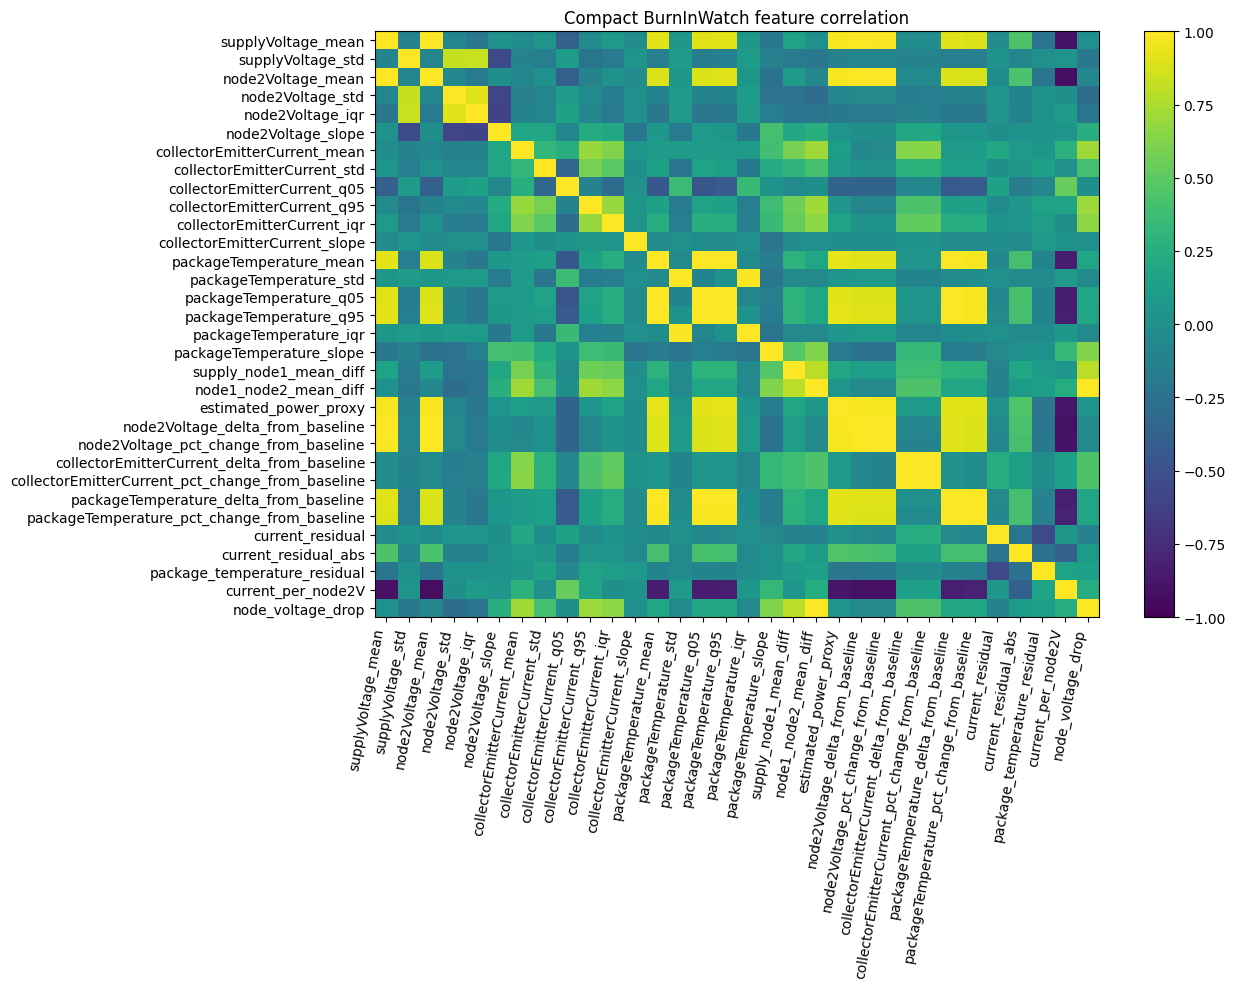

In [9]:
corr = core[MODEL_CANDIDATES].corr()

fig, ax = plt.subplots(figsize=(13, 10))
im = ax.imshow(corr.values, aspect="auto", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.index)))
ax.set_xticklabels(corr.columns, rotation=80, ha="right")
ax.set_yticklabels(corr.index)
ax.set_title("Compact BurnInWatch feature correlation")
fig.colorbar(im, ax=ax)

plt.tight_layout()
plt.show()

## 9. Compare early-vs-late distributions

We do not label late measurements as "faulty".

Instead, this diagnostic checks whether the engineered response variables shift between:
- first 20% of a source file
- last 20% of a source file

A systematic shift would support the idea that the representation captures aging-related change.

In [10]:
# ============================================================
# 9. EARLY VS LATE DIAGNOSTIC
# ============================================================

diagnostic_features = [
    "collectorEmitterCurrent_mean",
    "current_residual",
    "current_residual_abs",
    "packageTemperature_mean",
    "package_temperature_residual",
    "node2Voltage_mean",
    "node2Voltage_delta_from_baseline",
]

diagnostic_features = [
    c for c in diagnostic_features
    if c in core.columns
]

diagnostic_rows = []

for (device_id, file_name), group in core.groupby(
    ["device_id", "file_name"]
):
    group = group.sort_values("window_index")

    n = len(group)
    split = max(1, int(np.floor(n * 0.20)))

    early = group.iloc[:split]
    late = group.iloc[-split:]

    for feature in diagnostic_features:
        diagnostic_rows.append({
            "device_id": device_id,
            "file_name": file_name,
            "feature": feature,
            "early_median": early[feature].median(),
            "late_median": late[feature].median(),
            "median_shift": (
                late[feature].median() -
                early[feature].median()
            ),
        })

diagnostic = pd.DataFrame(diagnostic_rows)

display(
    diagnostic.sort_values(
        ["feature", "device_id", "file_name"]
    )
)

,device_id,file_name,feature,early_median,late_median,median_shift
0,Device_2,Device2 1.mat,collectorEmitterCurrent_mean,0.109420,0.100967,-0.008453
7,Device_2,Device2b 1.mat,collectorEmitterCurrent_mean,0.102563,0.105800,0.003237
14,Device_2,Device2check 1.mat,collectorEmitterCurrent_mean,0.134813,0.134813,0.000000
21,Device_3,Device3 1.mat,collectorEmitterCurrent_mean,0.109158,0.101721,-0.007436
28,Device_3,Device3b 1.mat,collectorEmitterCurrent_mean,0.102038,0.106610,0.004571
...,...,...,...,...,...,...
39,Device_3,Device3check 1.mat,package_temperature_residual,NaN,NaN,NaN
46,Device_4,Device4 1.mat,package_temperature_residual,-0.965304,159.887012,160.852315
53,Device_4,Device4b 1.mat,package_temperature_residual,0.946391,-88.002592,-88.948983
60,Device_5,Device5 1.mat,package_temperature_residual,1.096119,-49.567710,-50.663830


In [11]:
# ============================================================
# 10. SAVE V2 FEATURE DATASETS — FIXED
# ============================================================

# Metadata that actually exists in `core`.
BASE_META = [
    "device_id",
    "file_name",
    "file_role",
    "window_index",
    "window_size",
    "window_start_seconds",
    "window_end_seconds",
]

# Baseline/reference columns are useful for diagnostics, but they
# are NOT automatically model features.
BASELINE_META = [
    c for c in [
        "supplyVoltage_baseline",
        "node2Voltage_baseline",
        "collectorEmitterCurrent_baseline",
        "packageTemperature_baseline",
        "expected_current",
        "expected_package_temperature",
    ]
    if c in core.columns
]

# Make sure every requested feature exists before selecting it.
def existing(cols):
    return [c for c in cols if c in core.columns]

absolute_cols = existing(BASE_META + ABSOLUTE_SET)
relative_cols = existing(BASE_META + RELATIVE_SET + BASELINE_META)
residual_cols = existing(BASE_META + RESIDUAL_SET + BASELINE_META)
relation_cols = existing(BASE_META + RELATION_SET)

all_candidate_cols = existing(
    BASE_META +
    ABSOLUTE_SET +
    RELATIVE_SET +
    RESIDUAL_SET +
    RELATION_SET
)

# Save feature-group datasets.
core[absolute_cols].to_csv(
    PROCESSED / "burninwatch_features_absolute_v2.csv",
    index=False
)

core[relative_cols].to_csv(
    PROCESSED / "burninwatch_features_relative_v2.csv",
    index=False
)

core[residual_cols].to_csv(
    PROCESSED / "burninwatch_features_residual_v2.csv",
    index=False
)

core[relation_cols].to_csv(
    PROCESSED / "burninwatch_features_relationship_v2.csv",
    index=False
)

core[all_candidate_cols].to_csv(
    PROCESSED / "burninwatch_features_candidates_v2.csv",
    index=False
)

diagnostic.to_csv(
    PROCESSED / "burninwatch_early_late_diagnostic.csv",
    index=False
)

print("Saved feature datasets:")
for name in [
    "burninwatch_features_absolute_v2.csv",
    "burninwatch_features_relative_v2.csv",
    "burninwatch_features_residual_v2.csv",
    "burninwatch_features_relationship_v2.csv",
    "burninwatch_features_candidates_v2.csv",
    "burninwatch_early_late_diagnostic.csv",
]:
    print(" -", PROCESSED / name)

Saved feature datasets:
 - processed\burninwatch_features_absolute_v2.csv
 - processed\burninwatch_features_relative_v2.csv
 - processed\burninwatch_features_residual_v2.csv
 - processed\burninwatch_features_relationship_v2.csv
 - processed\burninwatch_features_candidates_v2.csv
 - processed\burninwatch_early_late_diagnostic.csv


In [12]:
# ============================================================
# 11. VERIFY EXPORTED FILES
# ============================================================

export_files = sorted(PROCESSED.glob("burninwatch_*_v2.csv"))

for path in export_files:
    check = pd.read_csv(path, nrows=3)
    print(f"\n{path.name}: shape preview={check.shape}")
    print("Columns:", list(check.columns))

print("\nFeature candidates:", len(all_candidate_cols))
print("Example candidate columns:")
print(all_candidate_cols)


burninwatch_features_absolute_v2.csv: shape preview=(3, 28)
Columns: ['device_id', 'file_name', 'file_role', 'window_index', 'window_size', 'window_start_seconds', 'window_end_seconds', 'supplyVoltage_mean', 'supplyVoltage_std', 'node2Voltage_mean', 'node2Voltage_std', 'node2Voltage_iqr', 'node2Voltage_slope', 'collectorEmitterCurrent_mean', 'collectorEmitterCurrent_std', 'collectorEmitterCurrent_q05', 'collectorEmitterCurrent_q95', 'collectorEmitterCurrent_iqr', 'collectorEmitterCurrent_slope', 'packageTemperature_mean', 'packageTemperature_std', 'packageTemperature_q05', 'packageTemperature_q95', 'packageTemperature_iqr', 'packageTemperature_slope', 'supply_node1_mean_diff', 'node1_node2_mean_diff', 'estimated_power_proxy']

burninwatch_features_candidates_v2.csv: shape preview=(3, 42)
Columns: ['device_id', 'file_name', 'file_role', 'window_index', 'window_size', 'window_start_seconds', 'window_end_seconds', 'supplyVoltage_mean', 'supplyVoltage_std', 'node2Voltage_mean', 'node2Volt

# STOP POINT

This notebook is now an exploratory feature-engineering stage.

We have deliberately kept the feature groups separate so that the
next modeling notebook can compare:
- absolute features
- relative-to-baseline features
- context residuals
- relationship features

Do NOT train Isolation Forest until we inspect the saved feature
datasets and decide the leakage-safe train/validation/test design.

We still need documentary confirmation of the unusual
`heatSinkTemperature` and `internalTemperature` scales before making
physical claims about them.